In [32]:
#To save to git!!! 
##git add "Roman Microlensing Data Challenge 2026.ipynb"
##git commit -m "update notebook"
##git push

In [33]:
#Install the packages we need 

%pip install -q huggingface_hub pyarrow pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [34]:
#Import the Python libraries we need 

from huggingface_hub import hf_hub_download

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [35]:
#Download the Beginner dataset 

file_path = hf_hub_download(
    repo_id="RGES-PIT/Beginner",
    filename="RMDC26_Beginner_Tier_test.parquet",
    repo_type="dataset"
)

#print the location of the downloaded file on your computer 
print(file_path)

/Users/maihaller/.cache/huggingface/hub/datasets--RGES-PIT--Beginner/snapshots/3d091e68f83662a843c9a5ef78b913c1b0e30848/RMDC26_Beginner_Tier_test.parquet


In [36]:
#Load in a select few colunmns, the ones you think will be most important 
## Name = event/target ID
## Bjd = time of the observation 
## filt = Roman filter 
## mag = measured magnitude 
## mag_err = uncertainity in that magnitude 
## saturation_flag = whether that measurement was saturated (0 = good, 1 = saturated) 

df = pd.read_parquet(
    file_path,
    columns=[
        "name",
        "bjd",
        "filt",
        "mag",
        "mag_err",
        "saturation_flag"
    ]
)

df.head()

,name,bjd,filt,mag,mag_err,saturation_flag
0,RMDC26_000001,2.461448e+06,F087,22.453972,0.081850,0
1,RMDC26_000001,2.461448e+06,F087,22.561998,0.090412,0
2,RMDC26_000001,2.461448e+06,F087,22.444434,0.081134,0
3,RMDC26_000001,2.461449e+06,F087,22.445701,0.081228,0
4,RMDC26_000001,2.461449e+06,F087,22.371004,0.075828,0


In [37]:
#Check how much data we have 

print("Number of observations:", len(df))
print("Number of targets:", df["name"].nunique())

Number of observations: 9230048
Number of targets: 188


In [38]:
#Let's pull ONE event now 

event_name = df["name"].iloc[0]

event = df[df["name"] == event_name].copy()

print(event_name)
print(len(event))

event.head()

RMDC26_000001
49096


,name,bjd,filt,mag,mag_err,saturation_flag
0,RMDC26_000001,2.461448e+06,F087,22.453972,0.081850,0
1,RMDC26_000001,2.461448e+06,F087,22.561998,0.090412,0
2,RMDC26_000001,2.461448e+06,F087,22.444434,0.081134,0
3,RMDC26_000001,2.461449e+06,F087,22.445701,0.081228,0
4,RMDC26_000001,2.461449e+06,F087,22.371004,0.075828,0


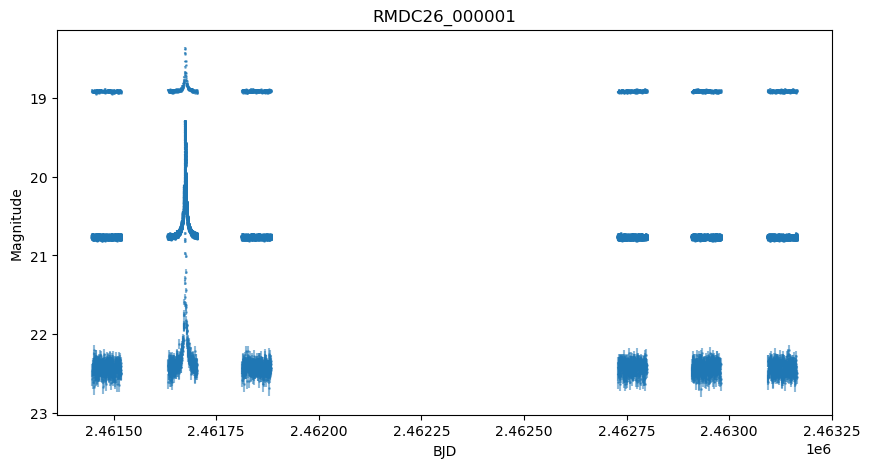

In [39]:
#Plot this event 

plt.figure(figsize=(10, 5))

plt.errorbar(
    event["bjd"],
    event["mag"],
    yerr=event["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

plt.xlabel("BJD")
plt.ylabel("Magnitude")
plt.title(event_name)

plt.gca().invert_yaxis()

plt.show()

In [40]:
# Look at all of the different filters used to observe this target.
#
# .unique() returns each distinct value that appears
# in the "filt" column.

event["filt"].unique()

array(['F087', 'F146', 'F213'], dtype=object)

In [41]:
# Count how many observations we have in each filter.
#
# value_counts() tells us how many rows belong
# to each distinct filter.

event["filt"].value_counts()

filt
F146    46208
F087     1445
F213     1443
Name: count, dtype: int64

In [42]:
#Target was observed in 3 filters 

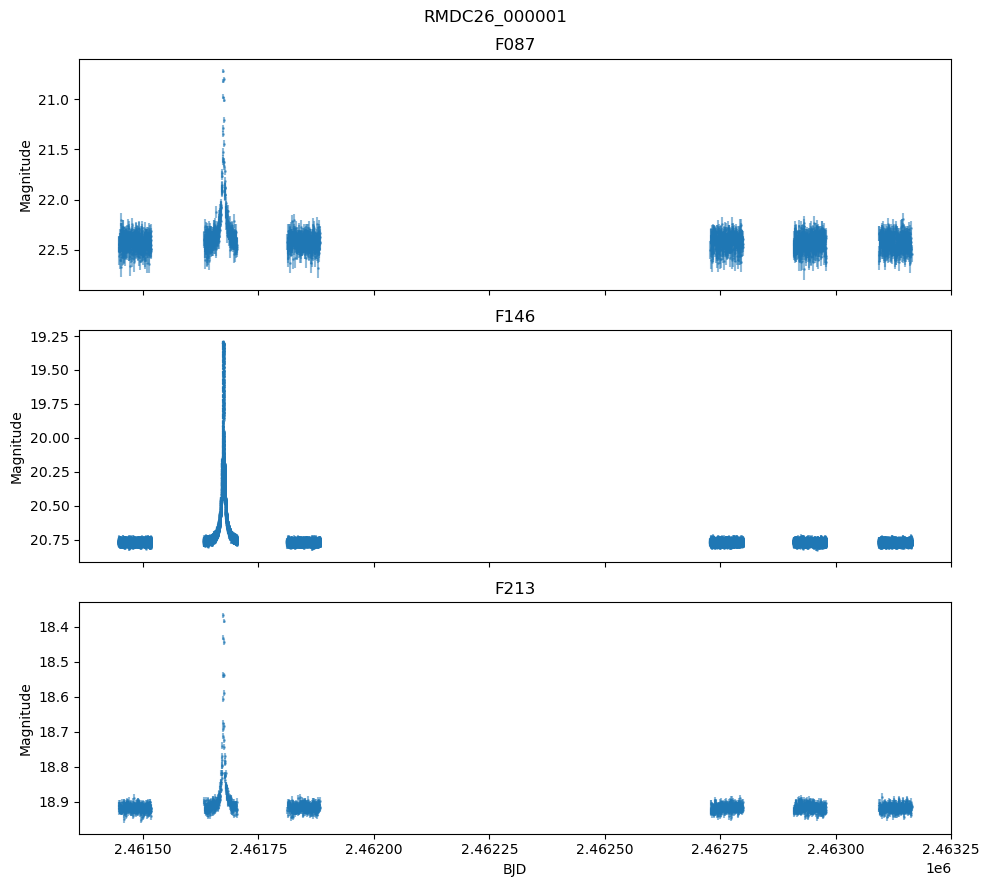

In [43]:
#Let's separate the filters

F087_data = event[event["filt"] == "F087"]
F146_data = event[event["filt"] == "F146"]
F213_data = event[event["filt"] == "F213"]


#Create 3 plots stacked vertically

#nrows = 3 means we want 3 rows of plots
#ncols = 1 means we want one plot per row
#sharex = True means all plots use the same BJD/time axis

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 9),
    sharex=True
)


#Plot F087

axes[0].errorbar(
    F087_data["bjd"],
    F087_data["mag"],
    yerr=F087_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[0].set_ylabel("Magnitude")
axes[0].set_title("F087")
axes[0].invert_yaxis()


#Plot F146

axes[1].errorbar(
    F146_data["bjd"],
    F146_data["mag"],
    yerr=F146_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[1].set_ylabel("Magnitude")
axes[1].set_title("F146")
axes[1].invert_yaxis()


#Plot F213

axes[2].errorbar(
    F213_data["bjd"],
    F213_data["mag"],
    yerr=F213_data["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

axes[2].set_ylabel("Magnitude")
axes[2].set_title("F213")
axes[2].invert_yaxis()


#Label the shared x-axis

axes[2].set_xlabel("BJD")


#Add the event name as the overall title

fig.suptitle(event_name)


#Fix spacing so labels do not overlap

plt.tight_layout()


#Display the plots

plt.show()

In [44]:
#Basic workflow

#1) Understand + clean data <-- where we are now
#2) Fit every target first with the simplest 1S1L model 
#3) Inspect residuals and decide whether 1S1L is adequate 
#4) Classify targets by the models they require 
#5) Fit more complicated events appropriately 
    #binary lens (1S2L), binary source (2S1L), finite-source/parallax effects when needed
#6) Build one results table for all 188 targets
#7) Save diagnostic plots and document methodogloy/computation 
#8) Run everything through microlens-submit validation 

In [ ]:
#Check how many saturated and unsaturated observations
#we have in each filter

event.groupby(["filt", "saturation_flag"]).size()

In [ ]:
#None of the measurements are saturated! That's good! 

#We can start estimating the model parameters 

#Start fitting F146 because it has the most observations 

In [ ]:
#Get an initial guess for t0 (time when the mircolensing event reaches maximum brightness)

#Select only F146 observations

F146_data = event[event["filt"] == "F146"].copy()


#Find the row with the smallest magnitude

#idxmin() gives us the row where mag is smallest
#Smallest magnitude = brightest observation

brightest_index = F146_data["mag"].idxmin()


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Get the magnitude at the brightest observation

peak_mag = F146_data.loc[brightest_index, "mag"]


#Print our first estimate for the event peak

print("t0 guess:", t0_guess)
print("Peak magnitude:", peak_mag)

In [ ]:
#Create a new column for time relative to our estimated peak

#At the peak, relative_time = 0
#Before the peak = negative time
#After the peak = positive time

F146_data["relative_time"] = F146_data["bjd"] - t0_guess


#Plot the F146 light curve relative to the peak

plt.figure(figsize=(10, 5))

plt.errorbar(
    
    #Time relative to the event peak
    F146_data["relative_time"],
    
    #Measured magnitude
    F146_data["mag"],
    
    #Magnitude uncertainty
    yerr=F146_data["mag_err"],
    
    #Plot observations as small dots
    fmt=".",
    markersize=2,
    alpha=0.5
)


#Label the axes

plt.xlabel("Days from estimated peak")
plt.ylabel("Magnitude")


#Add a title

plt.title(event_name + " - F146")max


#Smaller magnitude = brighter

plt.gca().invert_yaxis()


#Mark our estimated t0

#x = 0 because we defined the peak as relative_time = 0

plt.axvline(
    x=0,
    linestyle="--",
    label="Estimated t0"
)


#Show the label for the dashed line

plt.legend()


#Display the plot

plt.show()

In [ ]:

event_name = df["name"].iloc[424242]

print(event_name)

event = df[df["name"] == event_name].copy()

print(event_name)
print(len(event))

event.head()


plt.figure(figsize=(10, 5))

plt.errorbar(
    event["bjd"],
    event["mag"],
    yerr=event["mag_err"],
    fmt=".",
    markersize=2,
    alpha=0.5
)

plt.xlabel("BJD")
plt.ylabel("Magnitude")
plt.title(event_name)

plt.gca().invert_yaxis()

plt.show()

In [243]:
kk = 0

RMDC26_000031
t0 guess: 2461832.5848172
Peak magnitude: 19.412612326237245


/var/folders/87/9hyfwjnn3jg0bhvrkc4kkggw0000gn/T/ipykernel_92072/4237947090.py:117: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


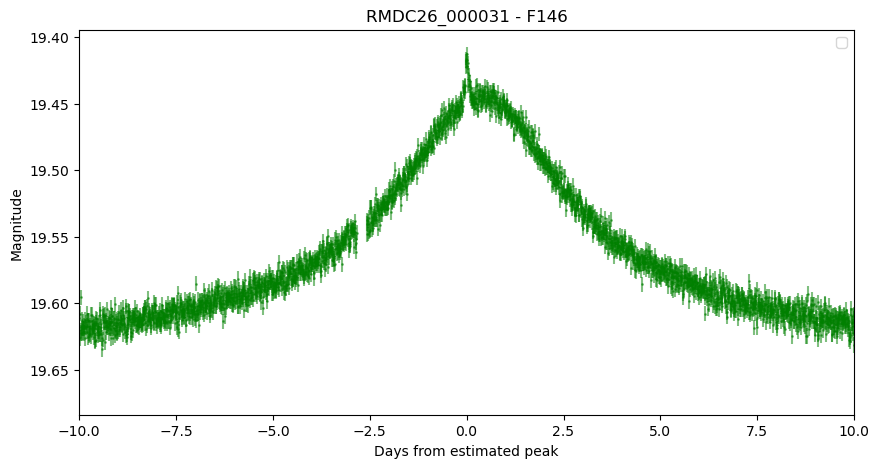

0


In [244]:
#RAPID FIRE

#kk -= 1 

e_names = list(set(df.name))

event_name = e_names[kk] 

#event_name = df["name"].iloc[424242]

print(event_name)

event = df[df["name"] == event_name].copy()



#Create a new column for time relative to our estimated peak

#At the peak, relative_time = 0
#Before the peak = negative time
#After the peak = positive time

F146_data = event[event["filt"] == "F146"].copy()

#Get an initial guess for t0 (time when the mircolensing event reaches maximum brightness)

#Select only F146 observations

F146_data = event[event["filt"] == "F146"].copy()


#Find the row with the smallest magnitude

#idxmin() gives us the row where mag is smallest
#Smallest magnitude = brightest observation

brightest_index = F146_data["mag"].idxmin()


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Get the magnitude at the brightest observation

peak_mag = F146_data.loc[brightest_index, "mag"]


#Print our first estimate for the event peak

print("t0 guess:", t0_guess)
print("Peak magnitude:", peak_mag)

F146_data["relative_time"] = F146_data["bjd"] - t0_guess


#Get the BJD of the brightest observation

t0_guess = F146_data.loc[brightest_index, "bjd"]


#Plot the F146 light curve relative to the peak

plt.figure(figsize=(10, 5))

plt.errorbar(
    
    #Time relative to the event peak
    F146_data["relative_time"],
    
    #Measured magnitude
    F146_data["mag"],
    
    #Magnitude uncertainty
    yerr=F146_data["mag_err"],
    
    #Plot observations as small dots
    fmt=".",
    markersize=2,
    alpha=0.5,
    color = "green"
)


#Label the axes

plt.xlabel("Days from estimated peak")
plt.ylabel("Magnitude")


#Add a title

plt.title(event_name + " - F146")


#Smaller magnitude = brighter

plt.gca().invert_yaxis()


#Mark our estimated t0

#x = 0 because we defined the peak as relative_time = 0

#plt.axvline(
   # x=t0_guess,
   # linestyle="--",
   # label="Estimated t0"
#)

plt.xlim(-10, 10)


#Show the label for the dashed line

plt.legend()


#Display the plot

plt.show()

print(kk)

kk+=1

In [ ]:
#single
#000002
#000163

#binary
#000178
#000051
#000091 (Free planet?)
#000108 (dimming event, planet?) 
#000051 (planet) 
#000122 (textbook event)
#000016 (caustic?) 
#000014
#000036
#000095 (horns)
#000006 (dimming) 
#000049 
#000003 (dimming) 
#000009
#000025
#000133 (dimming)
#000005 (crazy)
#000096
#000037
#000031
#000184 
#000039
#000113
#000099
#000019
#000026 (crazy)
#000176 (horns) 
#000050
#000031
#000039 (dimming)
#000122 
#000114 
#000171 (crazy?) 
#000003 (dimming)
#000045 (crazy?) 
#000150 
#000050
#000173
#000054
#000092 (crazy, horns?)
#000006 (dimming)
#000015
#000108 (dimming)
#000145 (dimming) 
#000041 (horns)
#000053 (crazy?)
#000047 (dimming)
#000026 (crazy)
#000143
#000025
#000169 (dimming?)

#undetermined
#000078
#000027
#000104
#000024
#000035
#000162
#000137
#000152
#000186
#000110
#000028
#000029
#000049
#000107
#000048
#000101 
#000177
#000005
#000138
#000020
#000096
#000014



#split into groups, horns, dimming, brightening, spikes, singles 
#if extra time, fit lens models to it 

In [245]:
print(len(df))

#Unique event names
print(len(set(df.name)))

print((set(df.name)))

9230048
188
{'RMDC26_000031', 'RMDC26_000152', 'RMDC26_000039', 'RMDC26_000122', 'RMDC26_000155', 'RMDC26_000140', 'RMDC26_000114', 'RMDC26_000171', 'RMDC26_000065', 'RMDC26_000058', 'RMDC26_000141', 'RMDC26_000009', 'RMDC26_000088', 'RMDC26_000003', 'RMDC26_000045', 'RMDC26_000179', 'RMDC26_000136', 'RMDC26_000074', 'RMDC26_000185', 'RMDC26_000022', 'RMDC26_000188', 'RMDC26_000133', 'RMDC26_000158', 'RMDC26_000186', 'RMDC26_000102', 'RMDC26_000066', 'RMDC26_000110', 'RMDC26_000070', 'RMDC26_000062', 'RMDC26_000073', 'RMDC26_000069', 'RMDC26_000010', 'RMDC26_000017', 'RMDC26_000170', 'RMDC26_000154', 'RMDC26_000132', 'RMDC26_000147', 'RMDC26_000131', 'RMDC26_000086', 'RMDC26_000028', 'RMDC26_000038', 'RMDC26_000016', 'RMDC26_000176', 'RMDC26_000099', 'RMDC26_000144', 'RMDC26_000123', 'RMDC26_000150', 'RMDC26_000187', 'RMDC26_000029', 'RMDC26_000019', 'RMDC26_000050', 'RMDC26_000049', 'RMDC26_000175', 'RMDC26_000104', 'RMDC26_000004', 'RMDC26_000042', 'RMDC26_000076', 'RMDC26_000173', '

In [246]:
#Now split into groups:

#Binary candidates
#├── horns
#├── dimming
#├── brightening
#└── crazy

#Single candidates

#Undetermined

In [247]:
#Split the binary candidates into groups

#Horns
horns = [
    "000041",
    "000092",   #crazy / horns?
    "000095",
    "000176"
]


#Dimming
dimming = [
    "000003",
    "000006",
    "000039",
    "000047",
    "000108",
    "000133",
    "000145",
    "000169"    #dimming?
]


#Crazy
crazy = [
    "000026",
    "000045",   #crazy?
    "000053",   #crazy?
    "000171"    #crazy?
]


#Brightening / other binary candidates
#These are the binary events that did not have a horns,
#dimming, or crazy note

brightening = [
    "000009",
    "000015",
    "000016",   #caustic?
    "000019",
    "000025",
    "000031",
    "000036",
    "000037",
    "000050",
    "000051",
    "000054",
    "000091",   #free planet?
    "000099",
    "000113",
    "000114",
    "000122",   #textbook event
    "000143",
    "000150",
    "000173",
    "000178",
    "000184"
]


#Events we were not confident about

undetermined = [
    "000005",
    "000014",
    "000020",
    "000024",
    "000027",
    "000028",
    "000029",
    "000035",
    "000048",
    "000049",
    "000078",
    "000096",
    "000101",
    "000104",
    "000107",
    "000110",
    "000137",
    "000138",
    "000152",
    "000162",
    "000177",
    "000186"
]

In [248]:
#Combine all binary groups

binary_ids = horns + dimming + crazy + brightening


#Convert our IDs into the full event names used in the dataset

binary_events = ["RMDC26_" + event_id for event_id in binary_ids]
undetermined_events = ["RMDC26_" + event_id for event_id in undetermined]


#Get every event in the Beginner dataset

all_events = set(df["name"].unique())


#Anything we did not mark as binary or undetermined
#will automatically be considered a single candidate

singles = sorted(
    all_events
    - set(binary_events)
    - set(undetermined_events)
)

In [250]:
#Check how many candidates are in each group
#Create singles and undetermined groups

print("Horns:", len(horns))
print("Dimming:", len(dimming))
print("Crazy:", len(crazy))
print("Brightening:", len(brightening))

print("Total binary:", len(binary_ids))
print("Undetermined:", len(undetermined))
print("Singles:", len(singles))


#Make sure every event has been accounted for

total = len(binary_ids) + len(undetermined) + len(singles)

print("Total classified:", total)
print("Total events:", len(all_events))

Horns: 4
Dimming: 8
Crazy: 4
Brightening: 21
Total binary: 37
Undetermined: 22
Singles: 129
Total classified: 188
Total events: 188


In [251]:
#Create a dictionary connecting each event to its group

groups = {}

for event_id in horns:
    groups["RMDC26_" + event_id] = "horns"

for event_id in dimming:
    groups["RMDC26_" + event_id] = "dimming"

for event_id in crazy:
    groups["RMDC26_" + event_id] = "crazy"

for event_id in brightening:
    groups["RMDC26_" + event_id] = "brightening"

for event_name in undetermined_events:
    groups[event_name] = "undetermined"

for event_name in singles:
    groups[event_name] = "single"


#Turn everything into a DataFrame

candidate_table = pd.DataFrame({
    "event": sorted(groups.keys())
})


#Add the group for each event

candidate_table["group"] = candidate_table["event"].map(groups)


#Display the table

candidate_table

,event,group
0,RMDC26_000001,single
1,RMDC26_000002,single
2,RMDC26_000003,dimming
3,RMDC26_000004,single
4,RMDC26_000005,undetermined
...,...,...
183,RMDC26_000184,brightening
184,RMDC26_000185,single
185,RMDC26_000186,undetermined
186,RMDC26_000187,single


In [252]:
#Check that the classification table looks correct


#Count how many events are in each group

print("EVENTS IN EACH GROUP:")
print(candidate_table["group"].value_counts())
print()


#Check how many total events are in the table

print("Total events:", len(candidate_table))


#Check for duplicate events

duplicate_events = candidate_table["event"].duplicated().sum()

print("Duplicate events:", duplicate_events)


#Check whether any event is missing a group

missing_groups = candidate_table["group"].isna().sum()

print("Events missing a group:", missing_groups)


#Check that we are only using the groups we expect

expected_groups = [
    "single",
    "horns",
    "dimming",
    "brightening",
    "crazy",
    "undetermined"
]

unexpected_groups = candidate_table[
    ~candidate_table["group"].isin(expected_groups)
]

print("Events with unexpected groups:", len(unexpected_groups))


#Make sure all 188 Roman targets are accounted for

dataset_events = set(df["name"].unique())
table_events = set(candidate_table["event"])

missing_events = dataset_events - table_events
extra_events = table_events - dataset_events

print("Events missing from table:", len(missing_events))
print("Events in table but not dataset:", len(extra_events))


#Print any problems if they exist

if len(missing_events) > 0:
    print("Missing:", sorted(missing_events))

if len(extra_events) > 0:
    print("Extra:", sorted(extra_events))

if len(unexpected_groups) > 0:
    print("Unexpected groups:")
    print(unexpected_groups)


#Final check

if (
    len(candidate_table) == 188
    and duplicate_events == 0
    and missing_groups == 0
    and len(missing_events) == 0
    and len(extra_events) == 0
    and len(unexpected_groups) == 0
):
    print()
    print("Everything looks good!")

EVENTS IN EACH GROUP:
group
single          129
undetermined     22
brightening      21
dimming           8
crazy             4
horns             4
Name: count, dtype: int64

Total events: 188
Duplicate events: 0
Events missing a group: 0
Events with unexpected groups: 0
Events missing from table: 0
Events in table but not dataset: 0

Everything looks good!
